# 01 - Exploratory data analysis

UCI Heart Disease (Cleveland). Run `make data` first so `data/processed/heart_clean.csv` exists.

Each plot is produced by `mlops_project.data.eda`, which also saves it to `reports/figures/` for the report. Write your own observations in the *Observation* cells; do not paste generated text.

In [1]:
import pandas as pd
from IPython.display import Image, display

from mlops_project.config import DESCRIPTIONS, RAW_PATH
from mlops_project.data import eda
from mlops_project.data.preprocess import load_clean

pd.set_option("display.width", 120)
df = load_clean()
print(df.shape)
df.head()

(297, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0,6,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3,3,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2,7,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0,3,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0,3,0


## 1. Data quality
Missing values in the raw file, and the types of the cleaned file.

In [2]:
raw = pd.read_csv(RAW_PATH)
print("Raw rows:", len(raw), "| cleaned rows:", len(df))
raw.isna().sum()[raw.isna().any()]

Raw rows: 303 | cleaned rows: 297


ca      4
thal    2
dtype: int64

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 297 entries, 0 to 296
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       297 non-null    int64  
 1   sex       297 non-null    int64  
 2   cp        297 non-null    int64  
 3   trestbps  297 non-null    int64  
 4   chol      297 non-null    int64  
 5   fbs       297 non-null    int64  
 6   restecg   297 non-null    int64  
 7   thalach   297 non-null    int64  
 8   exang     297 non-null    int64  
 9   oldpeak   297 non-null    float64
 10  slope     297 non-null    int64  
 11  ca        297 non-null    int64  
 12  thal      297 non-null    int64  
 13  target    297 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 32.6 KB


## 2. Data dictionary

In [4]:
pd.Series(DESCRIPTIONS, name="meaning").to_frame()

,meaning
age,Age (years)
sex,"Sex (1 = male, 0 = female)"
cp,"Chest pain type (1 typical angina, 2 atypical,..."
trestbps,Resting blood pressure (mm Hg)
chol,Serum cholesterol (mg/dl)
fbs,Fasting blood sugar > 120 mg/dl (1 = true)
restecg,"Resting ECG result (0 normal, 1 ST-T abnormali..."
thalach,Maximum heart rate achieved
exang,Exercise-induced angina (1 = yes)
oldpeak,ST depression induced by exercise relative to ...


## 3. Class balance

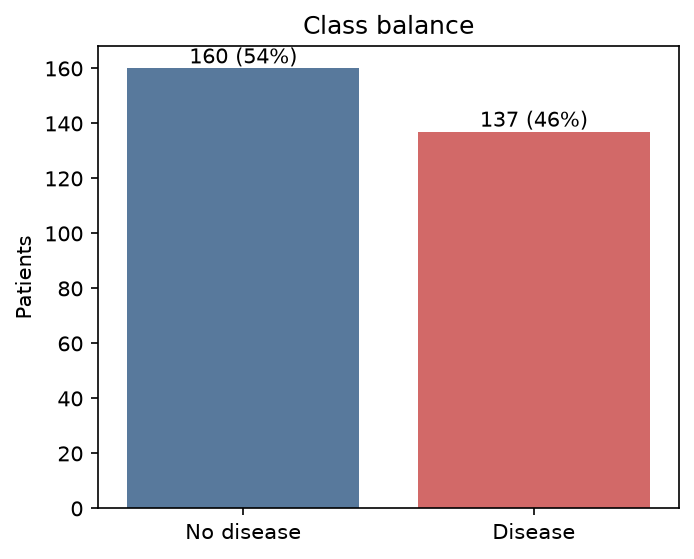

In [5]:
display(Image(eda.plot_class_balance(df)))

**Observation:** The classes are close to balanced: 160 patients without disease and 137 with it (54% / 46%), so no resampling is needed and accuracy is a fair headline number. I still report precision, recall and ROC-AUC, because missing a patient who has the disease costs more than a false alarm.

## 4. Numeric features

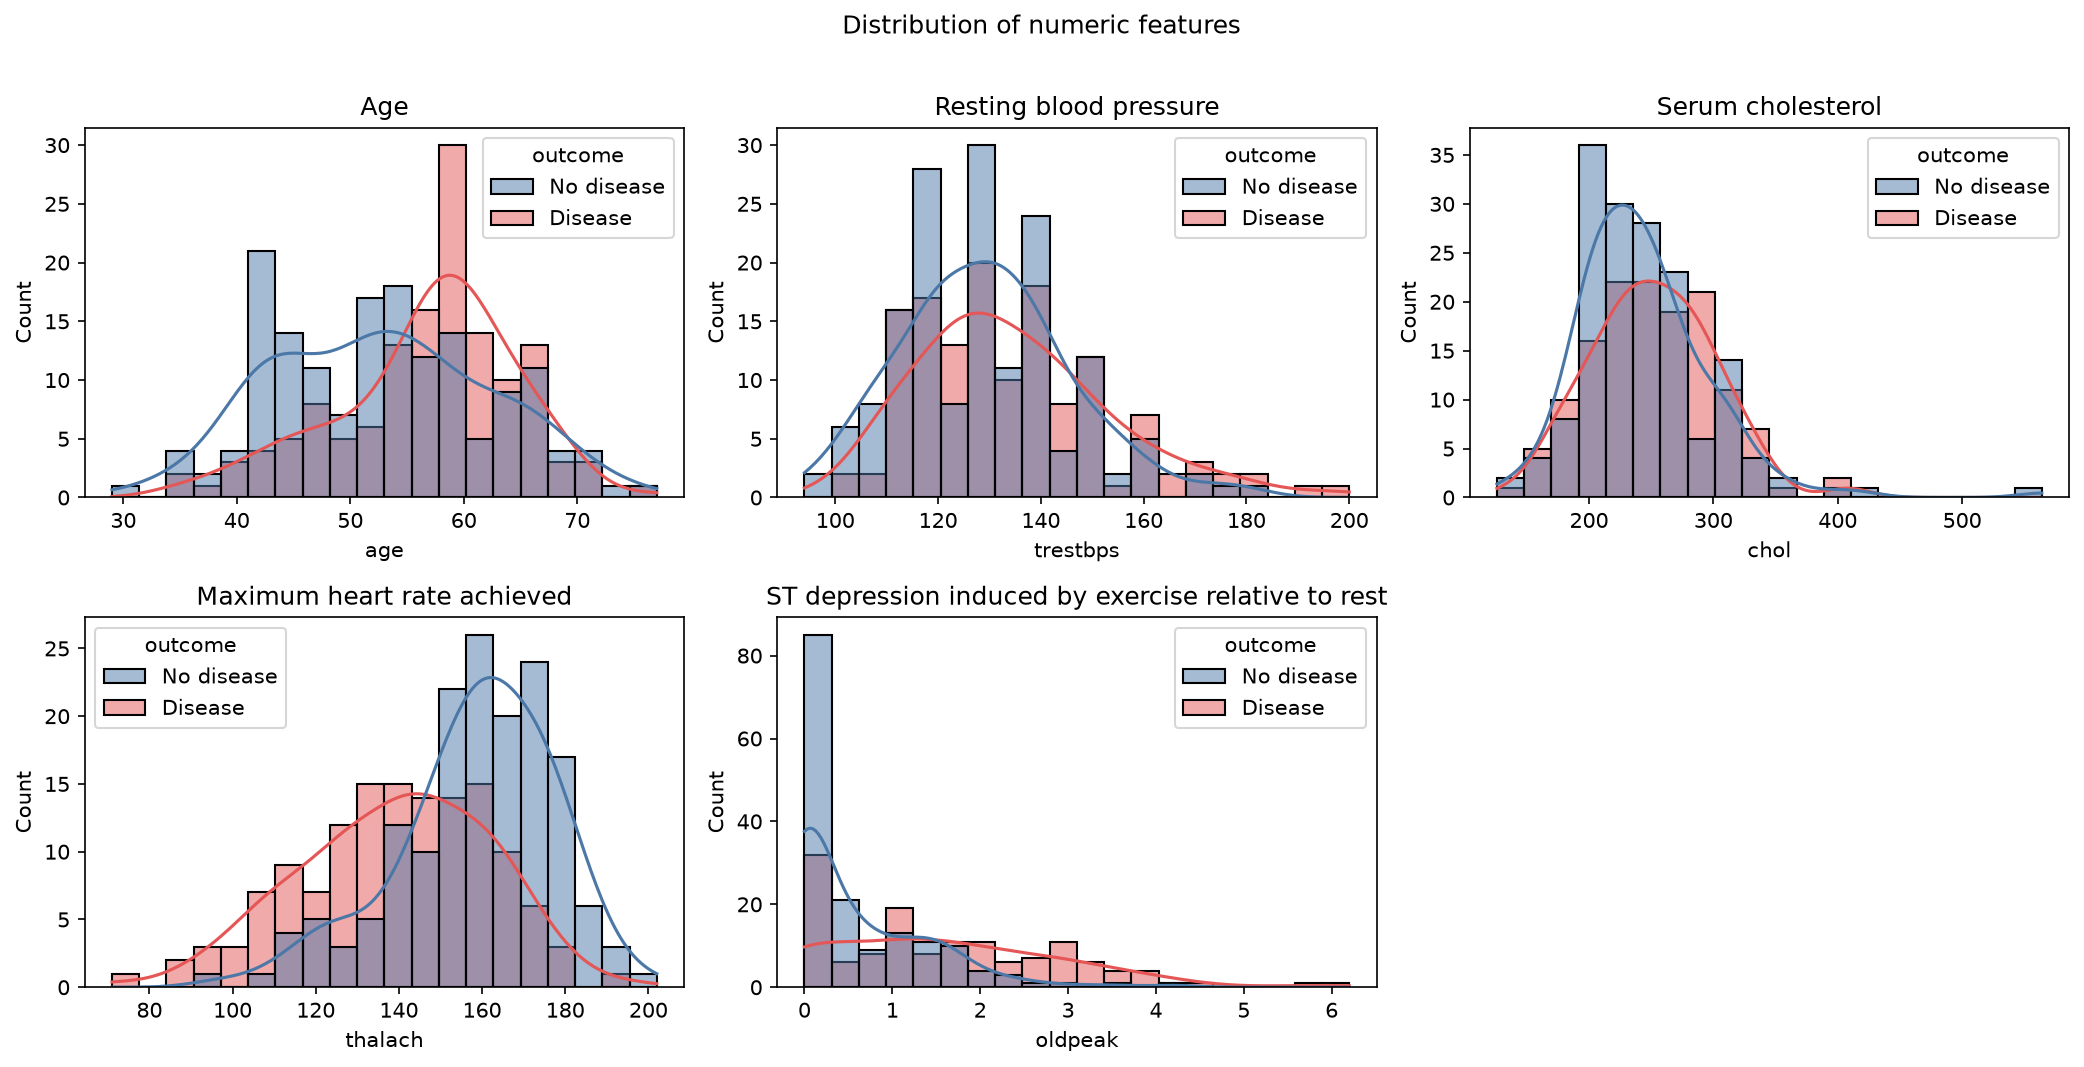

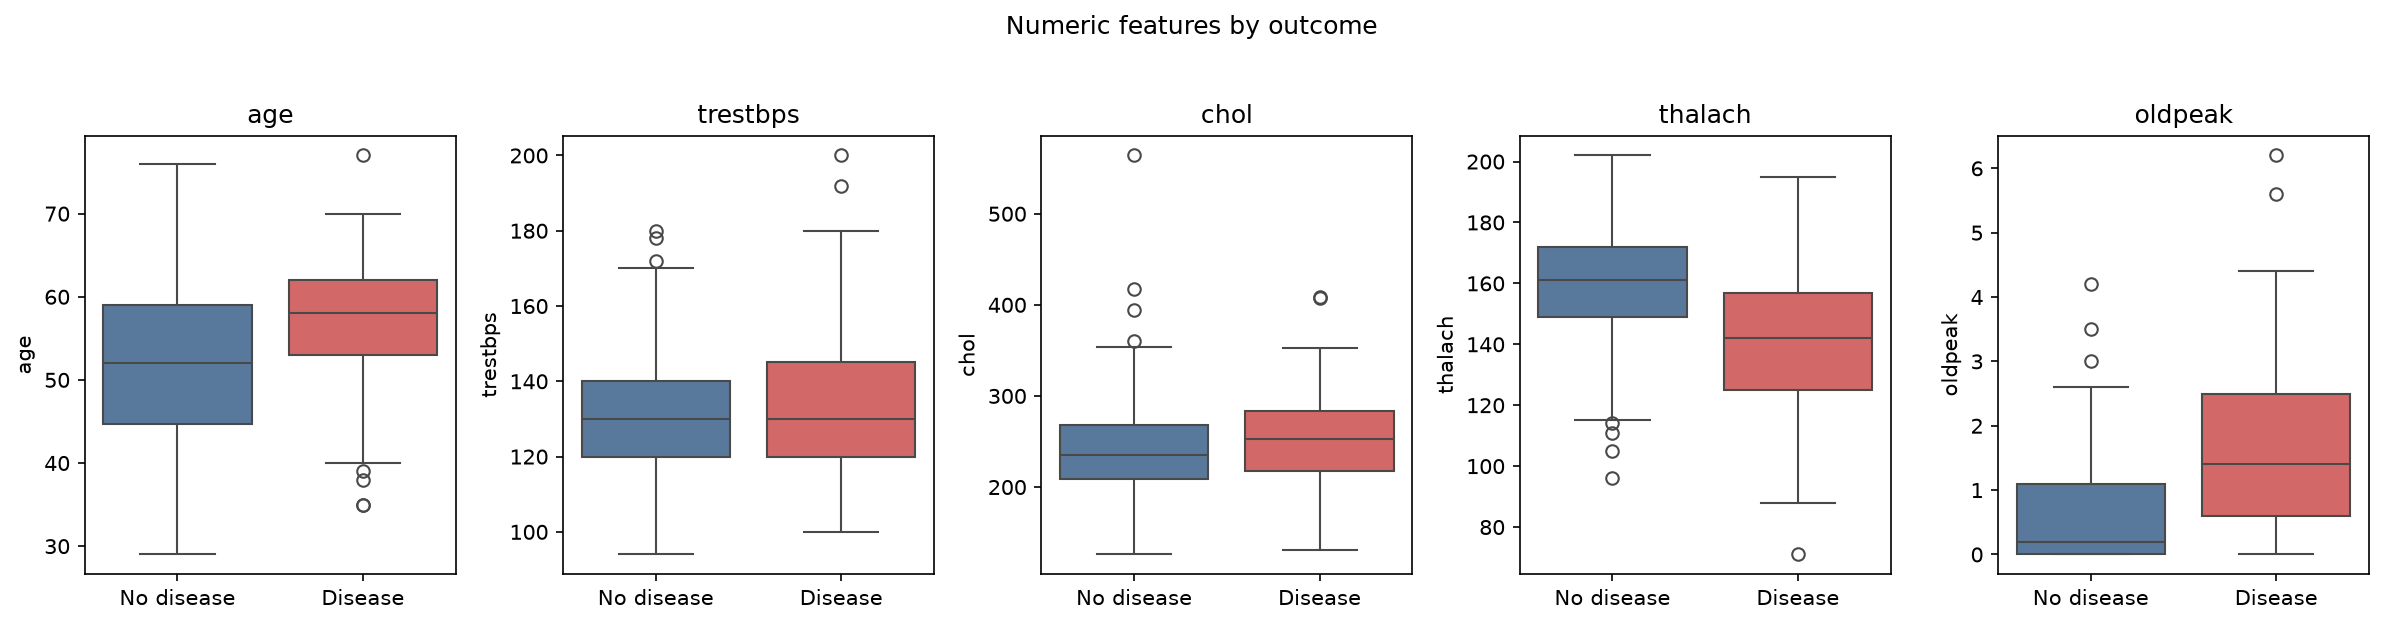

In [6]:
display(Image(eda.plot_numeric_histograms(df)))
display(Image(eda.plot_boxplots_by_target(df)))

**Observation:** Maximum heart rate (`thalach`) and ST depression (`oldpeak`) separate the groups best. Patients with disease have a lower mean `thalach` (139 vs 159) and a higher mean `oldpeak` (1.6 vs 0.6), and they are slightly older (57 vs 53). Resting blood pressure and cholesterol overlap heavily between the groups. `chol` has a few extreme values (maximum 564, four above 400) and `oldpeak` has a long right tail up to 6.2. I kept them because they are plausible clinical readings and only 297 rows are available.

## 5. Categorical features

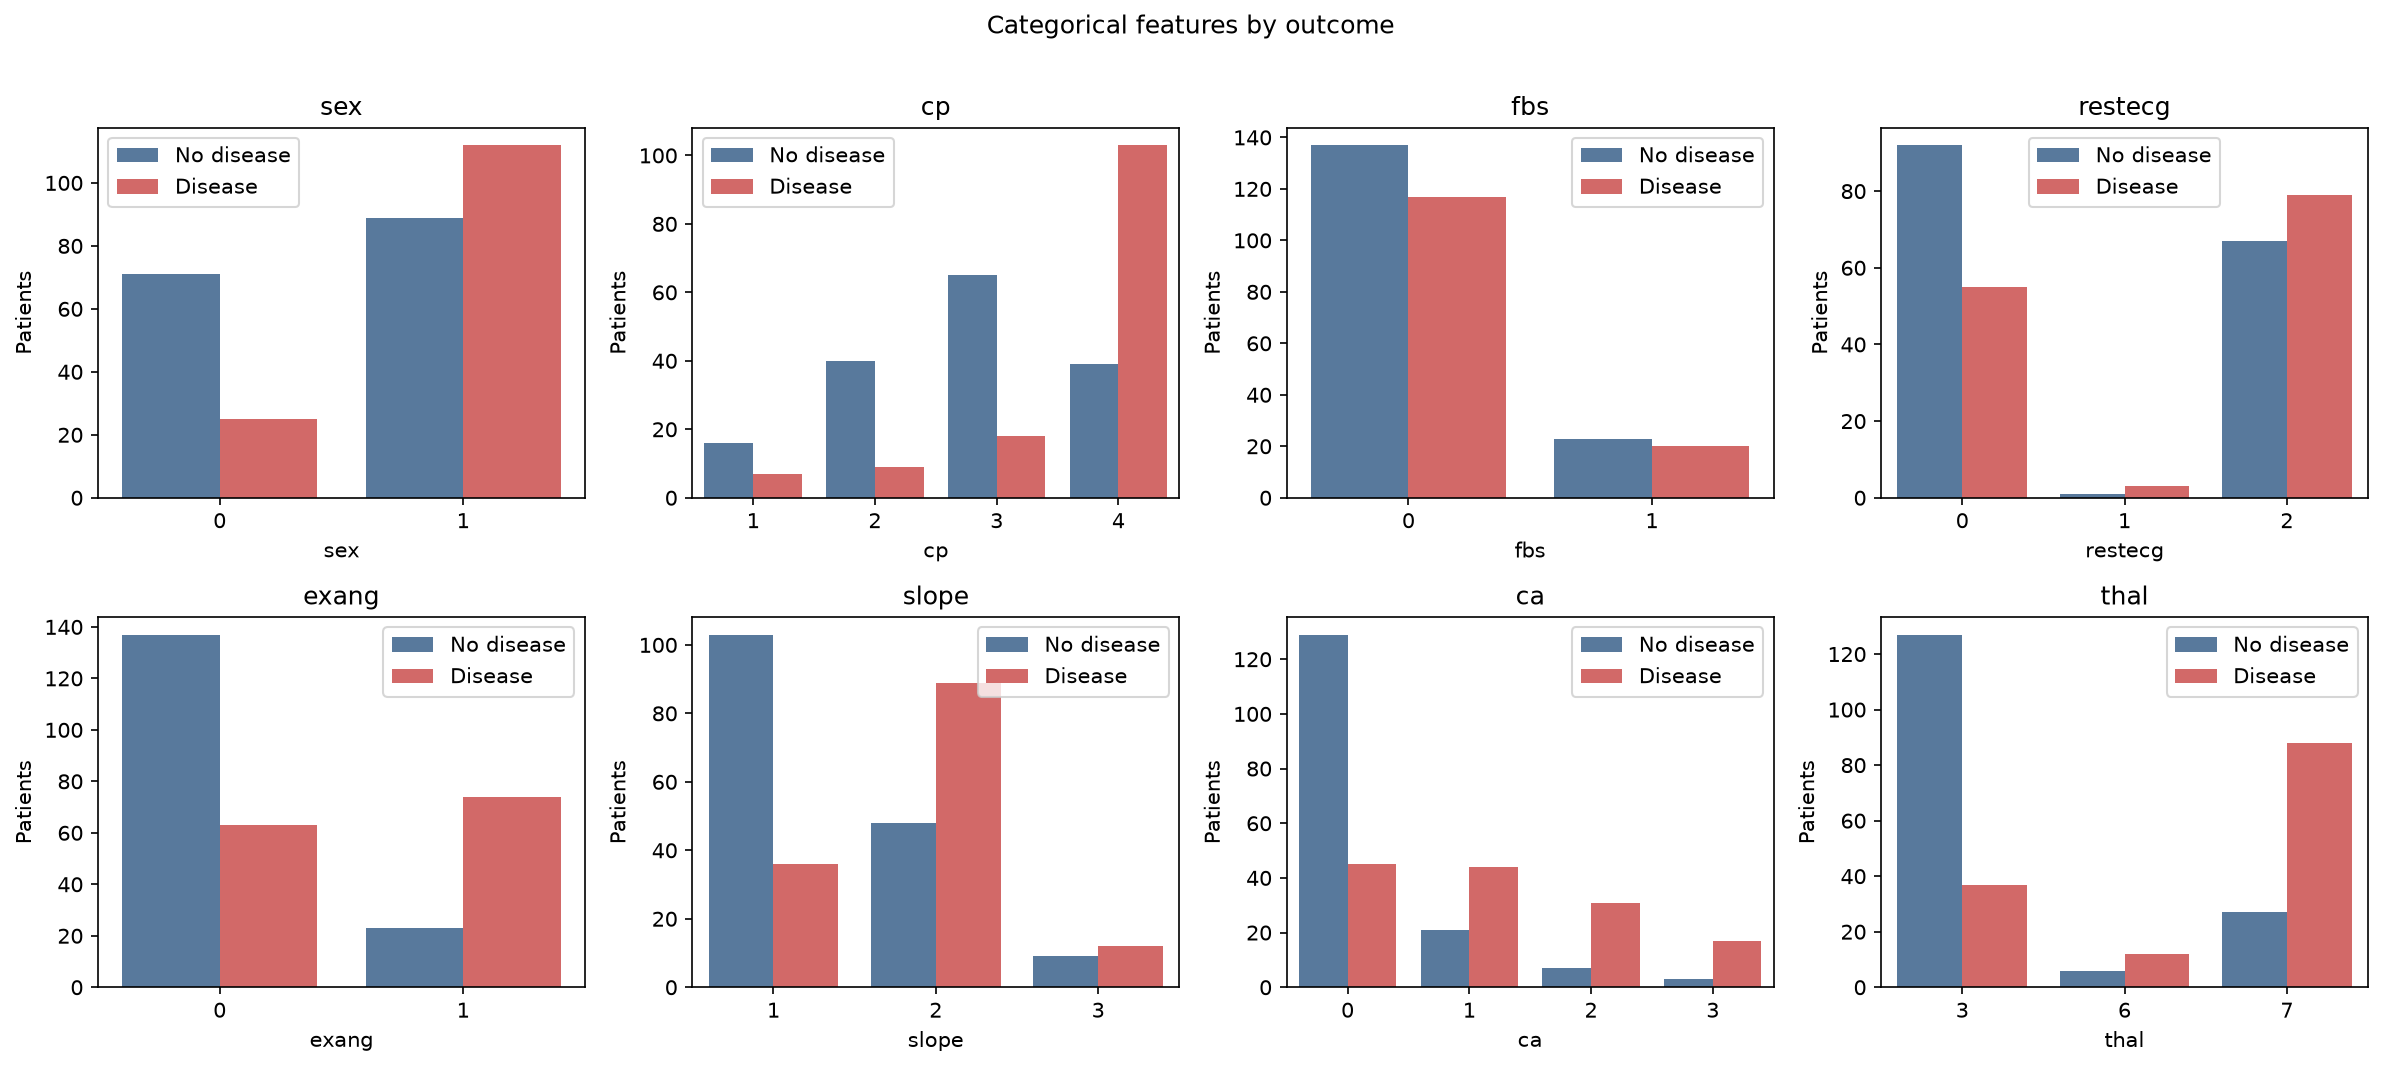

In [7]:
display(Image(eda.plot_categorical_counts(df)))

**Observation:** The disease rate is far higher for chest pain type 4 (73%, against 18-30% for the other types), for exercise-induced angina (76% vs 32%), for thal 7 (77%) and thal 6 (67%) against 23% for thal 3, and it rises with the number of coloured vessels (26% for `ca` 0 up to 85% for `ca` 3). Men have a higher rate than women (56% vs 26%). Fasting blood sugar shows no difference (46% vs 47%), so it is probably a weak feature. Some groups are small (`restecg` 1 has 4 patients, thal 6 has 18), so those rates are noisy.

## 6. Correlations

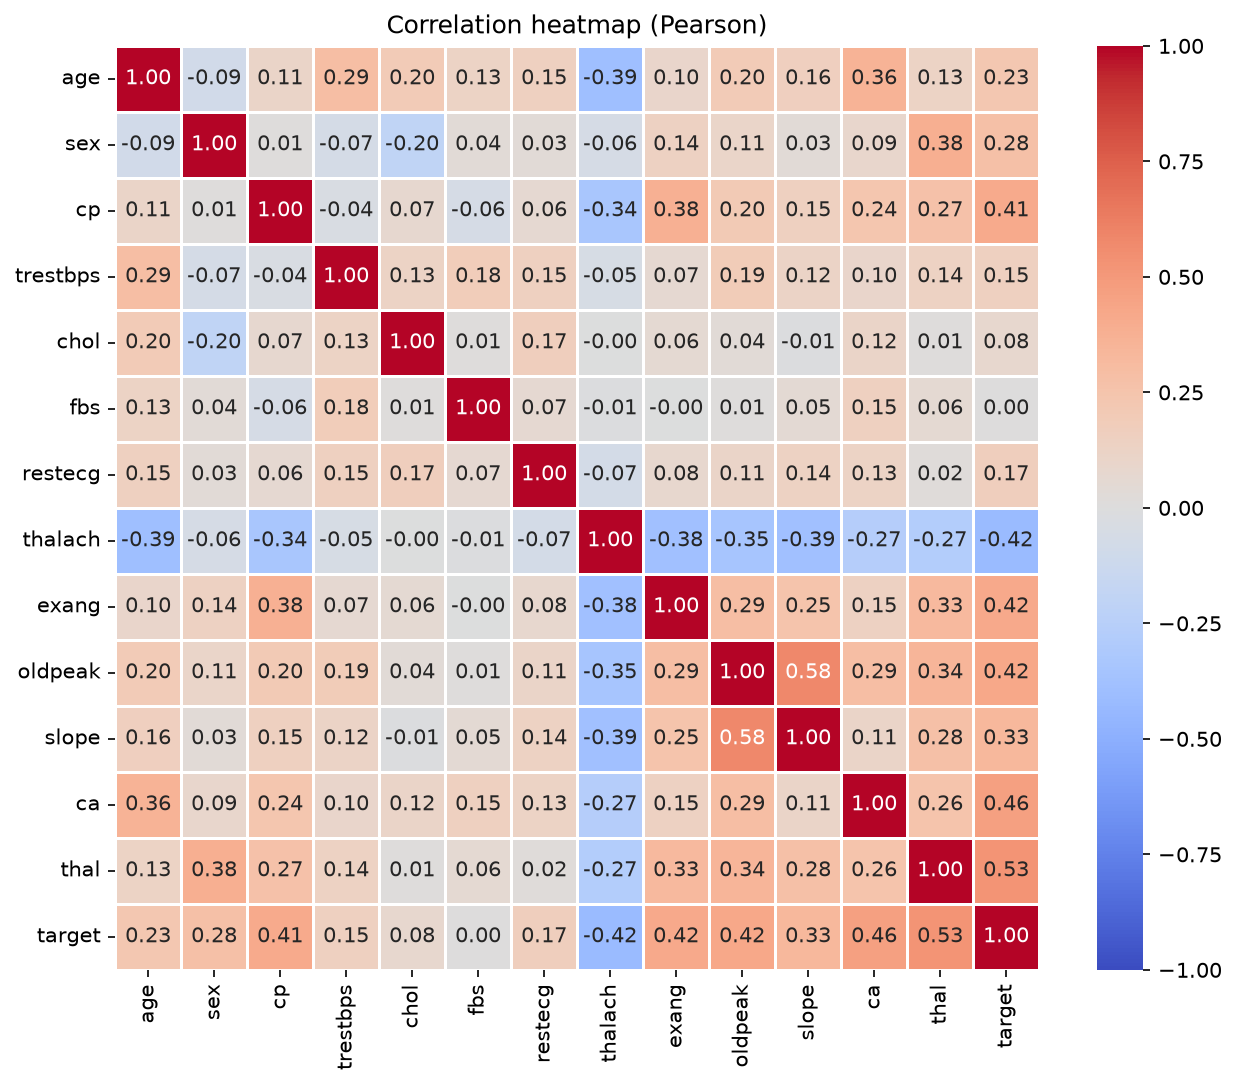

In [8]:
display(Image(eda.plot_correlation_heatmap(df)))

**Observation:** The strongest correlations with the target are `thal` (0.53), `ca` (0.46), `oldpeak` (0.42), `exang` (0.42), `thalach` (-0.42) and `cp` (0.41); `chol` (0.08) and `fbs` (0.00) are close to zero. Between features the highest pair is `oldpeak` and `slope` (0.58), followed by `age` and `thalach` (-0.39). Nothing is above 0.6, so collinearity is not a serious problem for logistic regression. Pearson correlation on coded categories is only a rough guide.

## 7. Summary numbers
Auto-generated facts to check your observations against.

In [9]:
print(eda.write_summary(df).read_text())

# EDA summary (auto-generated)

- Rows: 297, columns: 14
- Missing values: 0

## Class balance
- No disease: 160 (53.9%)
- Disease: 137 (46.1%)

## Correlation with the target (Pearson, strongest first)
- thal: +0.527
- ca: +0.463
- oldpeak: +0.424
- thalach: -0.424
- exang: +0.421
- cp: +0.409
- slope: +0.333
- sex: +0.278
- age: +0.227
- restecg: +0.166
- trestbps: +0.153
- chol: +0.080
- fbs: +0.003

Note: categorical codes (cp, thal, ...) are treated as numbers here, so these are
rough indicators; the model pipeline one-hot encodes them properly.

## Outliers by the 1.5 x IQR rule (numeric features)
- age: 0
- trestbps: 9
- chol: 5
- thalach: 1
- oldpeak: 5

## Numeric summary
```
          age  trestbps    chol  thalach  oldpeak
count  297.00    297.00  297.00   297.00   297.00
mean    54.54    131.69  247.35   149.60     1.06
std      9.05     17.76   52.00    22.94     1.17
min     29.00     94.00  126.00    71.00     0.00
25%     48.00    120.00  211.00   133.00     0.00
50%   